In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from das_tools import maps
from das_tools.utils import proj_path

TITLE_FONTSIZE = 18
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
LEGEND_FONTSIZE = 12

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.size": LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})

GEOTIFF_PATH = proj_path.data_dir("satellite", "20250503_050318_ssc4_u0001_visual_clip.tif")
RESULTS_DIR = proj_path.output_dir("tap_localization")
MAP_PAD_KM = 0.15            # margin around the cable and hammers, panel (a)
ZOOM_CHANNELS = (470, 654)  # panel (b): the bend, where the taps are densest
ZOOM_PAD_KM = 0.03

CABLE_COLOR = "red"
HAMMER_COLOR = "yellow"

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUT_PDF = FIGURE_DIR / "walked_route_full_cable.pdf"

In [2]:
channels = pd.read_csv(RESULTS_DIR / "channel_geometry.csv")
anchors = pd.read_csv(RESULTS_DIR / "tap_anchors.csv")
off_route = channels["source"].str.startswith("off_route").to_numpy()
# Assigned channel of each tap (canonical channels are whole numbers here).
k = anchors["channel_canonical"].round().astype(int).to_numpy()

bm_full = maps.load_basemap(
    GEOTIFF_PATH,
    *maps.points_box(np.r_[channels["lon"], anchors["lon"]],
                     np.r_[channels["lat"], anchors["lat"]], pad_km=MAP_PAD_KM),
)
zoom = channels["channel"].between(*ZOOM_CHANNELS).to_numpy()
bm_zoom = bm_full.crop(
    *maps.points_box(channels.loc[zoom, "lon"], channels.loc[zoom, "lat"], pad_km=ZOOM_PAD_KM))

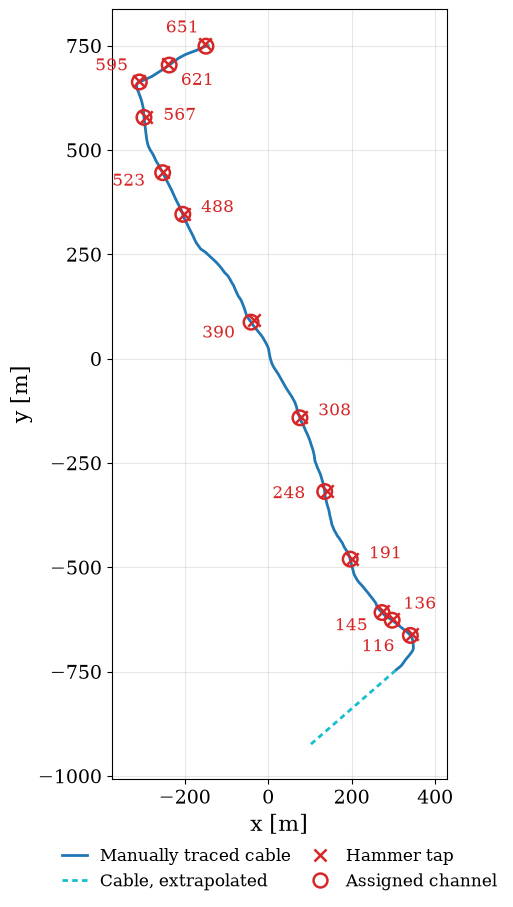

Saved: figures/walked_route_xy.pdf


In [3]:
CABLE_XY_COLOR = "tab:blue"
OFF_ROUTE_XY_COLOR = "tab:cyan"
TAP_XY_COLOR = "tab:red"
OUT_PDF_XY = FIGURE_DIR / "walked_route_xy.pdf"

x_ch, y_ch = channels["x_m"].to_numpy(), channels["y_m"].to_numpy()
x_as, y_as = x_ch[k], y_ch[k]

fig, ax = plt.subplots(figsize=(5.5, 10))
ax.plot(np.where(off_route, np.nan, x_ch), np.where(off_route, np.nan, y_ch),
        color=CABLE_XY_COLOR, lw=2, zorder=3)
ax.plot(np.where(off_route, x_ch, np.nan), np.where(off_route, y_ch, np.nan),
        color=OFF_ROUTE_XY_COLOR, lw=2, ls=(0, (2, 1.5)), zorder=3)
ax.scatter(anchors["x_m"], anchors["y_m"], s=80, marker="x", color=TAP_XY_COLOR, linewidths=1.8,
           zorder=5)
ax.scatter(x_as, y_as, s=110, marker="o", facecolors="none", edgecolors=TAP_XY_COLOR,
           linewidths=1.8, zorder=4)

# Channel labels perpendicular to the cable, on alternating sides so
# neighbouring taps do not collide.
for n, (i, xa, ya) in enumerate(zip(k, x_as, y_as)):
    j0, j1 = max(i - 3, 0), min(i + 3, len(x_ch) - 1)
    t = np.array([x_ch[j1] - x_ch[j0], y_ch[j1] - y_ch[j0]])
    normal = np.array([-t[1], t[0]]) / np.hypot(*t) * (1 if n % 2 == 0 else -1)
    ax.annotate(f"{i}", (xa, ya), xytext=14 * normal, textcoords="offset points",
                ha="left" if normal[0] >= 0 else "right", va="center",
                fontsize=12, color=TAP_XY_COLOR, zorder=6)

ax.set_aspect("equal")
ax.set_xlim(x_ch.min() - 60, x_ch.max() + 80)
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.grid(alpha=0.3)
ax.legend(handles=[
    Line2D([], [], color=CABLE_XY_COLOR, lw=2, label="Manually traced cable"),
    Line2D([], [], color=OFF_ROUTE_XY_COLOR, lw=2, ls=(0, (2, 1.5)), label="Cable, extrapolated"),
    Line2D([], [], marker="x", ls="none", ms=9, mew=1.8, color=TAP_XY_COLOR, label="Hammer tap"),
    Line2D([], [], marker="o", ls="none", ms=10, mew=1.8, mfc="none", mec=TAP_XY_COLOR,
           label="Assigned channel"),
], loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, frameon=False,
          handlelength=1.5, columnspacing=1.0)

fig.savefig(OUT_PDF_XY, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_PDF_XY}")